In [3]:
import pandas as pd

df = pd.read_csv("/archive.zip")
print(df.shape)
df.head()

(50000, 53)


,customer_id,customer_segment,segment_category,age,age_group,gender,country,city,income_bracket,education_level,...,customer_value_category,activity_status,health_status,churn_risk_category,rfm_category,profitability_category,engagement_level,behavior_segment,device_preference,clv_category
0,CUST-000001,Consumer,High Value Inactive,70,65+,Male,Canada,Winnipeg,150K+,Professional,...,High,Dormant,Excellent,Low,Potential Loyalists,High Profit,Low,Regular Buyer,Multi-Device,High CLV
1,CUST-000002,Premium,High Value Inactive,53,45-54,Female,Germany,Essen,25K-50K,High School,...,Medium,Inactive,Excellent,Medium,At Risk,High Profit,Low,Occasional Buyer,Desktop-First,High CLV
2,CUST-000003,Consumer,High Value Inactive,82,65+,Male,Mexico,Puebla,75K-100K,Bachelors,...,Very High,Dormant,Excellent,Very Low,Champions,High Profit,Low,Regular Buyer,Multi-Device,High CLV
3,CUST-000004,Enterprise,High Value Active,18,18-24,Male,Singapore,Singapore,150K+,Masters,...,Very High,Active,Excellent,Very Low,Champions,High Profit,High,Frequent Buyer,Mobile-First,High CLV
4,CUST-000005,Premium,High Value Active,64,55-64,Male,United Arab Emirates,Fujairah,150K+,PhD,...,Medium,Active,Fair,Medium,Loyal,High Profit,Medium,Occasional Buyer,Desktop-First,High CLV


In [4]:
# 1. Tipos de datos y cantidad de valores no nulos por columna
df.info()

# 2. Cuántos valores vacíos tiene cada columna (solo las que tienen)
nulos = df.isnull().sum()
print(nulos[nulos > 0])

# 3. Cuántas filas duplicadas hay
print("Duplicados:", df.duplicated().sum())

# 4. Estadísticas de las variables numéricas
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 53 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    50000 non-null  object 
 1   customer_segment               50000 non-null  object 
 2   segment_category               50000 non-null  object 
 3   age                            50000 non-null  int64  
 4   age_group                      50000 non-null  object 
 5   gender                         50000 non-null  object 
 6   country                        50000 non-null  object 
 7   city                           50000 non-null  object 
 8   income_bracket                 50000 non-null  object 
 9   education_level                50000 non-null  object 
 10  employment_type                50000 non-null  object 
 11  marital_status                 50000 non-null  object 
 12  tenure_months                  50000 non-null 

,count,mean,std,min,25%,50%,75%,max
age,50000.0,45.648020,18.367950,18.00,30.0000,45.000,60.00000,84.00
tenure_months,50000.0,59.748240,34.310128,1.00,30.0000,60.000,90.00000,119.00
total_purchases,50000.0,99.418460,57.780178,0.00,49.0000,99.000,150.00000,199.00
avg_order_value_usd,50000.0,505.366911,285.604037,10.05,259.0675,504.790,752.70250,999.99
total_spent_usd,50000.0,50266.546156,44071.209164,0.00,13893.5775,37541.625,76811.24250,198574.14
days_since_last_purchase,50000.0,62.971240,93.281404,0.00,2.0000,19.000,77.00000,365.00
return_count,50000.0,9.511740,5.782592,0.00,4.0000,10.000,15.00000,19.00
complaint_count,50000.0,6.993800,4.324250,0.00,3.0000,7.000,11.00000,14.00
satisfaction_score,50000.0,3.007960,1.417976,1.00,2.0000,3.000,4.00000,5.00
email_open_rate,50000.0,0.500319,0.289515,0.00,0.2510,0.500,0.75200,1.00


In [5]:
# Clientes que nunca compraron
print("Sin compras:", (df["total_purchases"] == 0).sum())

# ¿Qué significan los vacíos en estas dos columnas?
print(df["loyalty_tier"].value_counts(dropna=False))
print(df["social_media_presence"].value_counts(dropna=False))

# Quitamos la columna que no aporta
df = df.drop(columns=["dataset_year"])

Sin compras: 262
loyalty_tier
Diamond     20300
Platinum    10535
Gold         9446
Bronze       4259
Silver       4188
NaN          1272
Name: count, dtype: int64
social_media_presence
NaN                             12420
Twitter                          2217
Facebook                         2181
YouTube                          2079
LinkedIn                         2052
                                ...  
YouTube, Facebook, Instagram       85
Facebook, Twitter, TikTok          82
Facebook, LinkedIn, TikTok         80
Twitter, YouTube, TikTok           78
YouTube, Twitter, Facebook         78
Name: count, Length: 157, dtype: int64


In [6]:
# Los vacíos tienen significado, no son datos perdidos
df["loyalty_tier"] = df["loyalty_tier"].fillna("Sin nivel")
df["social_media_presence"] = df["social_media_presence"].fillna("Ninguna")

# Separamos a los clientes que nunca compraron
sin_compras = df[df["total_purchases"] == 0].copy()
df_clean = df[df["total_purchases"] > 0].copy()

print("Clientes para segmentar:", df_clean.shape)
print("Clientes sin compras:", sin_compras.shape)

Clientes para segmentar: (49738, 52)
Clientes sin compras: (262, 52)


       recencia  frecuencia  monetario
count  49738.00    49738.00   49738.00
mean      62.96       99.94   50531.33
std       93.27       57.48   44035.47
min        0.00        1.00      17.97
25%        2.00       50.00   14180.21
50%       19.00      100.00   37875.44
75%       77.00      150.00   77144.11
max      365.00      199.00  198574.14

Sesgo (skew):
recencia      1.76
frecuencia    0.00
monetario     0.97
dtype: float64


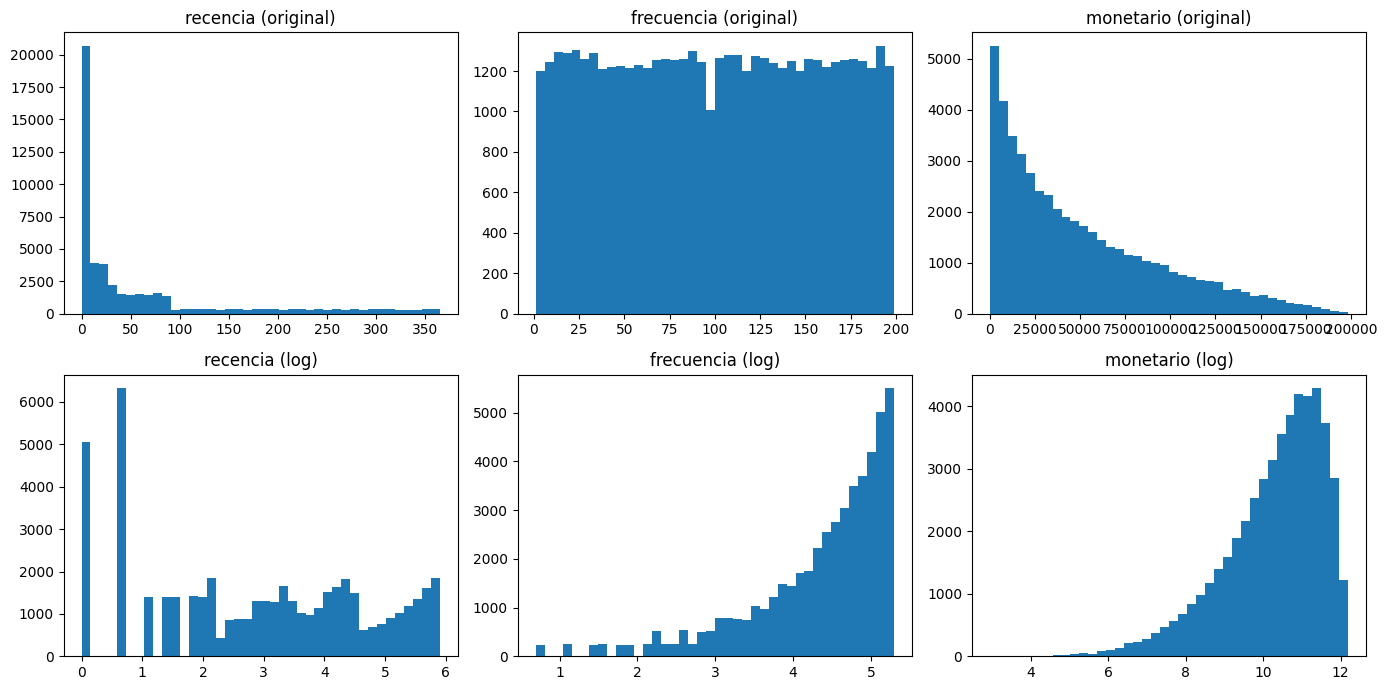

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Tabla RFM con nombres cortos
rfm = df_clean[["customer_id", "days_since_last_purchase", "total_purchases", "total_spent_usd"]].copy()
rfm.columns = ["customer_id", "recencia", "frecuencia", "monetario"]

print(rfm.describe().round(2))
print("\nSesgo (skew):")
print(rfm[["recencia", "frecuencia", "monetario"]].skew().round(2))

# Histogramas: arriba valores originales, abajo con logaritmo
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, col in enumerate(["recencia", "frecuencia", "monetario"]):
    axes[0, i].hist(rfm[col], bins=40)
    axes[0, i].set_title(f"{col} (original)")
    axes[1, i].hist(np.log1p(rfm[col]), bins=40)
    axes[1, i].set_title(f"{col} (log)")
plt.tight_layout()
plt.show()

recencia     -0.03
frecuencia    0.00
monetario     0.21
dtype: float64


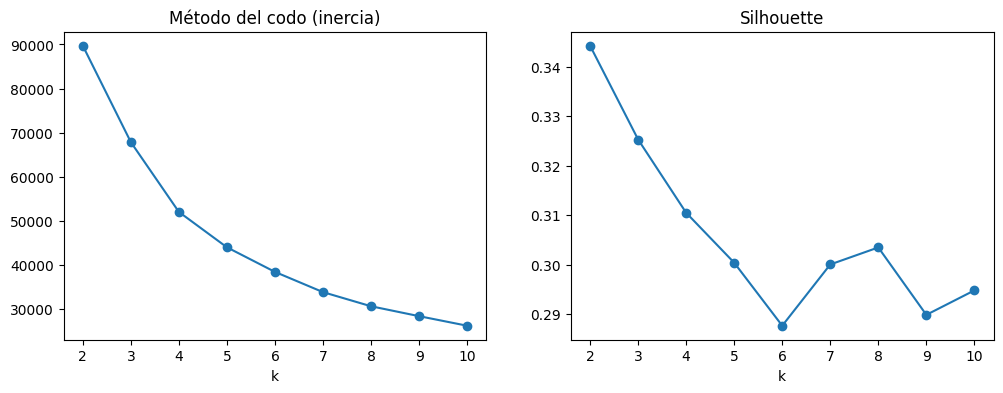

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Transformación elegida para cada variable según su sesgo
rfm_t = pd.DataFrame({
    "recencia": np.log1p(rfm["recencia"]),
    "frecuencia": rfm["frecuencia"],
    "monetario": np.sqrt(rfm["monetario"]),
})
print(rfm_t.skew().round(2))

# Escalado: las tres variables quedan con media 0 y desviación 1
X = StandardScaler().fit_transform(rfm_t)

# Probamos de 2 a 10 grupos
ks = range(2, 11)
inercia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=10000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inercia, marker="o")
ax[0].set_title("Método del codo (inercia)")
ax[0].set_xlabel("k")
ax[1].plot(ks, sil, marker="o")
ax[1].set_title("Silhouette")
ax[1].set_xlabel("k")
plt.show()

         clientes  recencia_mediana  frecuencia_mediana  monetario_mediano  \
cluster                                                                      
0           13713              70.0               148.0            76371.0   
1           13347              70.0                49.0            15099.0   
2           11258               1.0               149.0            77602.0   
3           11420               1.0                51.0            15510.0   

         pct_clientes  
cluster                
0                27.6  
1                26.8  
2                22.6  
3                23.0  


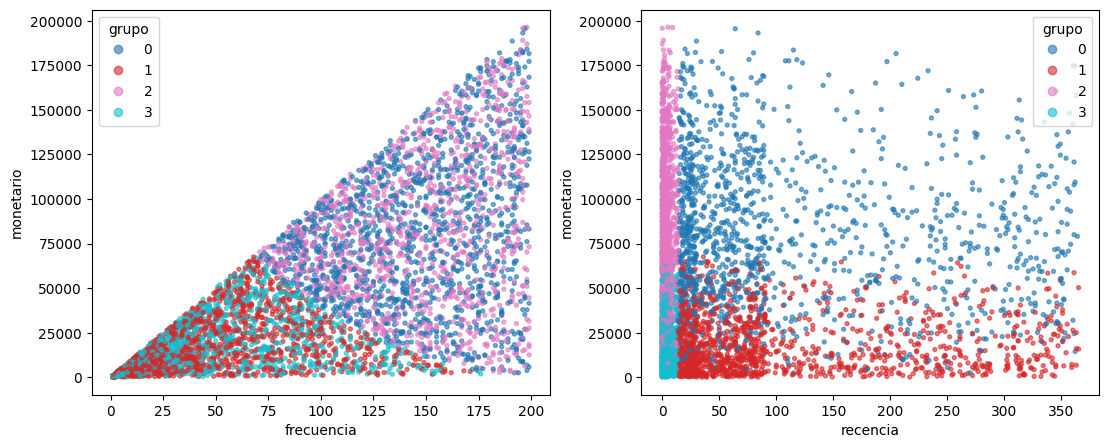

In [9]:
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X)
rfm["cluster"] = km.labels_

# Perfil de cada grupo
perfil = rfm.groupby("cluster").agg(
    clientes=("customer_id", "size"),
    recencia_mediana=("recencia", "median"),
    frecuencia_mediana=("frecuencia", "median"),
    monetario_mediano=("monetario", "median"),
).round(0)
perfil["pct_clientes"] = (perfil["clientes"] / len(rfm) * 100).round(1)
print(perfil)

# Gráficas con una muestra de 5,000 clientes
muestra = rfm.sample(5000, random_state=42)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (x, y) in zip(ax, [("frecuencia", "monetario"), ("recencia", "monetario")]):
    sc = a.scatter(muestra[x], muestra[y], c=muestra["cluster"], cmap="tab10", s=8, alpha=0.6)
    a.set_xlabel(x)
    a.set_ylabel(y)
    a.legend(*sc.legend_elements(), title="grupo")
plt.show()

In [10]:
nombres = {
    2: "Campeones",
    0: "Valiosos en riesgo",
    3: "Activos de bajo gasto",
    1: "Dormidos de bajo valor",
}
rfm["segmento"] = rfm["cluster"].map(nombres)

# ¿Qué tanto coincide con la etiqueta rfm_category original?
comparacion = rfm.merge(df_clean[["customer_id", "rfm_category"]], on="customer_id")
print((pd.crosstab(comparacion["segmento"], comparacion["rfm_category"], normalize="index") * 100).round(1))

rfm_category            At Risk  Champions  Loyal  Need Attention  \
segmento                                                            
Activos de bajo gasto      10.8       29.0   39.7             0.0   
Campeones                   0.0       98.6    1.4             0.0   
Dormidos de bajo valor     29.8        8.1   24.6             7.5   
Valiosos en riesgo          0.5       54.5   35.1             0.0   

rfm_category            Potential Loyalists  
segmento                                     
Activos de bajo gasto                  20.5  
Campeones                               0.0  
Dormidos de bajo valor                 30.0  
Valiosos en riesgo                      9.9  


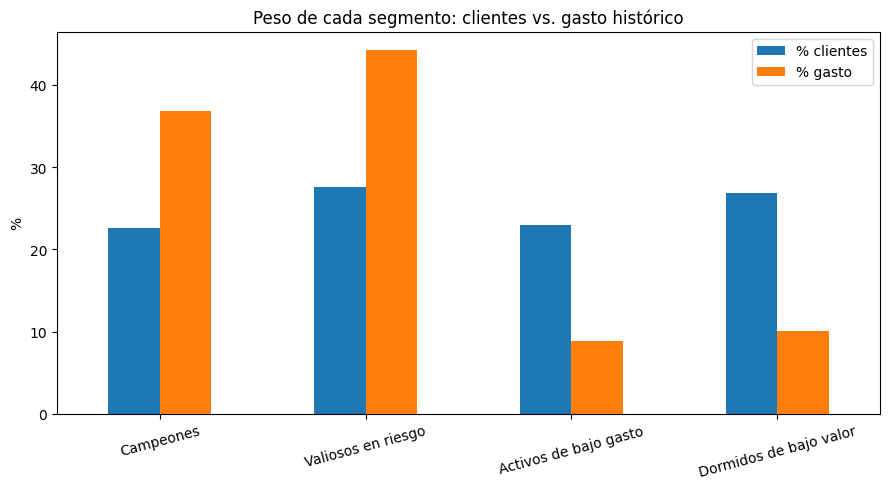

In [11]:
orden = ["Campeones", "Valiosos en riesgo", "Activos de bajo gasto", "Dormidos de bajo valor"]
resumen = rfm.groupby("segmento").agg(clientes=("customer_id", "size"), gasto=("monetario", "sum"))
resumen["% clientes"] = resumen["clientes"] / resumen["clientes"].sum() * 100
resumen["% gasto"] = resumen["gasto"] / resumen["gasto"].sum() * 100
resumen = resumen.loc[orden]

ax = resumen[["% clientes", "% gasto"]].plot(kind="bar", figsize=(9, 5))
ax.set_title("Peso de cada segmento: clientes vs. gasto histórico")
ax.set_ylabel("%")
ax.set_xlabel("")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("segmentos_clientes_vs_gasto.png", dpi=150)
plt.show()

rfm[["customer_id", "recencia", "frecuencia", "monetario", "segmento"]].to_csv("clientes_segmentados.csv", index=False)

In [12]:
from google.colab import files
files.download("segmentos_clientes_vs_gasto.png")
files.download("clientes_segmentados.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>